<a href="https://colab.research.google.com/github/LeonardoLuppi/honeybee-idbn-numerosity/blob/main/honeybee_idbn_simulation_thesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Setup, Imports, and Stimulus Generation (Refers to Section 2.3)This cell creates the $354 \times 354$ sharp external images. To save you time, this generator creates non-overlapping circles. You can scale the num_samples up to 2,400 for your final run over the weekend.

In [32]:
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.path import Path
import os, random


# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Use GPU if available (Colab T4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# =============================================================================
# SECTION 2.3: STIMULUS DATASET GENERATION
# =============================================================================
# Physical scaling: 6x6 cm card = 36 cm^2 -> 354x354 = 125,316 px (3,481 px/cm^2)
CARD_AREA_PX = 354 * 354
CONST_TOTAL_AREA_PX = 18000  # Physically scaled cumulative area allowing N=6 non-overlapping shapes
FIXED_ITEM_AREA_PX = 4500    # Fixed single-item area when constant_area=False


def _shape_bounding_radius(target_area, shape_type):
    """Exact circumradius (in pixels) for each supported geometric shape."""
    if shape_type == 'circle':
        return np.sqrt(target_area / np.pi)
    elif shape_type in ('square', 'diamond'):
        return np.sqrt(target_area / 2.0)
    elif shape_type == 'triangle':
        # Equilateral triangle: Area = (sqrt(3)/4) * s^2, circumradius R = s / sqrt(3)
        return np.sqrt((4.0 * target_area) / (3.0 * np.sqrt(3.0)))
    else:
        raise ValueError(f"Unknown shape_type: {shape_type}")


def _draw_shape_mask(x_grid, y_grid, cx, cy, target_area, shape_type):
    """Returns a boolean mask of a geometric shape centered at (cx, cy) with exact target_area."""
    dx = x_grid - cx
    dy = y_grid - cy

    if shape_type == 'circle':
        r = np.sqrt(target_area / np.pi)
        mask = (dx**2 + dy**2) <= r**2
        bound_r = r

    elif shape_type == 'square':
        half_s = np.sqrt(target_area) / 2.0
        mask = (np.abs(dx) <= half_s) & (np.abs(dy) <= half_s)
        bound_r = half_s * np.sqrt(2)

    elif shape_type == 'diamond':
        # Rotated square: |dx| + |dy| <= d, where Area = 2 * d^2
        d = np.sqrt(target_area / 2.0)
        mask = (np.abs(dx) + np.abs(dy)) <= d
        bound_r = d

    elif shape_type == 'triangle':
        # Equilateral triangle of side s: Area = (sqrt(3)/4) * s^2, circumradius R = s / sqrt(3)
        s = np.sqrt((4.0 * target_area) / np.sqrt(3.0))
        R = s / np.sqrt(3.0)
        angles = np.deg2rad([-90, 30, 150])
        verts = np.column_stack((cx + R * np.cos(angles), cy + R * np.sin(angles)))
        pts = np.column_stack((x_grid.ravel(), y_grid.ravel()))
        mask = Path(verts).contains_points(pts).reshape(x_grid.shape)
        bound_r = R

    else:
        raise ValueError(f"Unknown shape_type: {shape_type}")

    return mask, int(np.ceil(bound_r))


def generate_stimulus(N_items, img_size=354, constant_area=True, shape_type=None, max_restarts=200):
    """
    Generates a 354x354 sharp binary image of exactly N_items non-overlapping shapes
    (circles, squares, diamonds, or equilateral triangles) under constant or varying
    cumulative surface area controls (Howard et al., 2018; MaBouDi et al., 2021).
    """
    if N_items <= 0:
        return np.ones((img_size, img_size), dtype=np.float32)

    shapes_pool = ['circle', 'square', 'diamond', 'triangle']
    if shape_type is None:
        shape_type = np.random.choice(shapes_pool)

    # Add +/- 3% area jitter matching 10 +/- 0.3 cm^2 in Howard et al. (2018)
    area_jitter = np.random.uniform(0.97, 1.03)
    if constant_area:
        area_per_item = (CONST_TOTAL_AREA_PX * area_jitter) / N_items
    else:
        area_per_item = FIXED_ITEM_AREA_PX * area_jitter

    est_radius = int(np.ceil(np.sqrt(area_per_item / np.pi) * 1.35))
    exact_bound_r = int(np.ceil(_shape_bounding_radius(area_per_item, shape_type)))
    margin = max(est_radius, exact_bound_r) + 4

    y_grid, x_grid = np.meshgrid(np.arange(img_size), np.arange(img_size), indexing='ij')

    for _ in range(max_restarts):
        img = np.ones((img_size, img_size), dtype=np.float32)  # White background (1.0)
        positions = []
        success = True

        for _ in range(N_items):
            placed = False
            for _ in range(400):
                cx = np.random.randint(margin, img_size - margin)
                cy = np.random.randint(margin, img_size - margin)

                if any(np.hypot(cx - px, cy - py) < (2 * est_radius + 4) for (px, py) in positions):
                    continue

                mask, _ = _draw_shape_mask(x_grid, y_grid, cx, cy, area_per_item, shape_type)
                if not np.any(img[mask] == 0.0):  # Guarantee zero pixel overlap
                    img[mask] = 0.0  # Black item (0.0)
                    positions.append((cx, cy))
                    placed = True
                    break

            if not placed:
                success = False
                break

        if success:
            return img

    raise RuntimeError(
        f"Failed to place {N_items} non-overlapping '{shape_type}' items "
        f"(constant_area={constant_area}) within {max_restarts} restarts."
    )

# Test the generator
test_img = generate_stimulus(N_items=3, constant_area=True, shape_type='circle')

Using device: cpu


Cell 2: Biological Optical Filtering & Retinal Sampling (Refers to Section 2.1)This is where the physics of the honeybee eye happens. It computes the Fourier powers ($P_{bio}$ and $P_{high}$), applies the biological low-pass filter (keeping only harmonics $k \in [1, 9]$), and samples the blurred image into a $41 \times 41 = 1,681$ grid, which mathematically approximates the 1,685 binocular ommatidia observed by Seidl & Kaiser (1981).  

N=3 -> Max ommatidial activation: 1.000, P_bio: 0.10949, P_high: 0.01278
N=0 -> Max ommatidial activation: 0.000000 (Fixed: empty set is now at 0.0 baseline!)


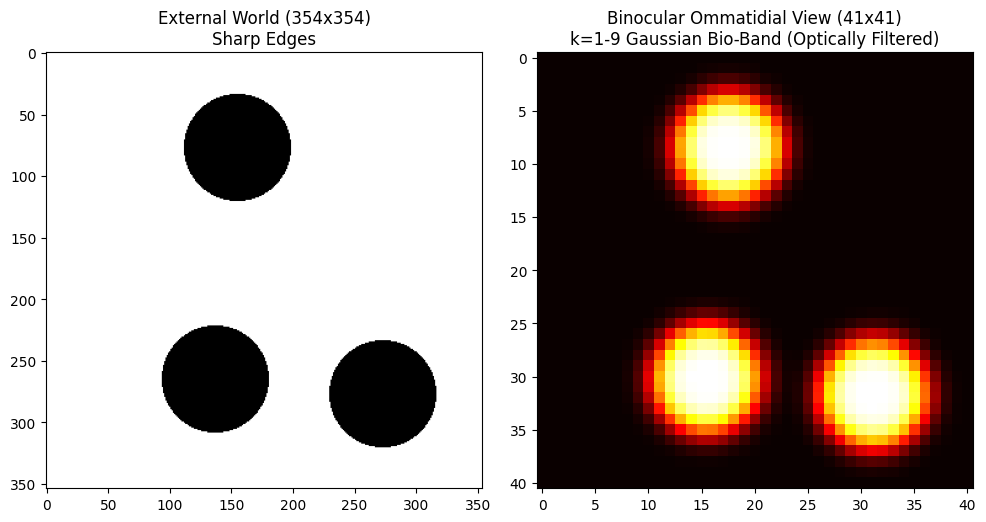

In [33]:
# =============================================================================
# SECTION 2.1: BIOLOGICALLY-PLAUSIBLE VISUAL FRONT-END
# =============================================================================
def apply_bee_optics(image, img_size=354, grid_size=41, sigma_k=5.5):
    """
    1. Computes 2D-DFT to extract radial spatial harmonics k.
    2. Calculates P_bio (k in [1, 9]) and P_high (k >= 10).
    3. Multiplies spectrum by an isotropic Gaussian Optical Transfer Function H(k)
       preserving k in [1, 9] (0.04-0.40 cpd) and attenuating k >= 10.
    4. Downsamples onto the 41x41 (1,681-unit) binocular ommatidial lattice
       without per-image min-max distortion (so N=0 remains 0.0 activation).
    """
    # 1. 2D Discrete Fourier Transform (shifted so DC k=0 is at center)
    fft2 = np.fft.fftshift(np.fft.fft2(image))

    center = img_size // 2
    y, x = np.ogrid[-center:img_size - center, -center:img_size - center]
    k_radius = np.sqrt(x**2 + y**2)

    # 2. Contiguous Fourier masks for biological passband vs. high-frequency band
    mask_bio  = (k_radius >= 0.5) & (k_radius < 9.5)   # Harmonics k in [1, 9]
    mask_high = (k_radius >= 9.5)                      # Harmonics k >= 10

    # Parseval-normalized spectral power
    norm_factor = float(img_size * img_size) ** 2
    P_bio  = np.sum(np.abs(fft2[mask_bio])**2) / norm_factor
    P_high = np.sum(np.abs(fft2[mask_high])**2) / norm_factor

    # 3. Isotropic Gaussian Optical Transfer Function H(k) (Section 2.1)
    # Corner frequency ~0.25 cpd (k ~ 5.65), strongly attenuating k >= 10 (>0.40 cpd)
    H_k = np.exp(-(k_radius**2) / (2.0 * (sigma_k**2)))
    fft2_filtered = fft2 * H_k

    # Inverse FFT to obtain filtered retinal luminance image in [0, 1]
    retinal_image = np.real(np.fft.ifft2(np.fft.ifftshift(fft2_filtered)))

    # Invert luminance BEFORE sampling so black shapes = 1.0 (active) and white card = 0.0 (rest)
    # Using fixed physical scale [0, 1] prevents N=0 empty cards from inverting to 1.0!
    retinal_activation = np.clip(1.0 - retinal_image, 0.0, 1.0)

    # 4. Spatial downsampling onto the 41x41 = 1,681 binocular ommatidial lattice
    retinal_tensor = torch.tensor(retinal_activation, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    sampled_ommatidia = F.interpolate(
        retinal_tensor, size=(grid_size, grid_size), mode='area'
    ).squeeze().numpy()

    return sampled_ommatidia, P_bio, P_high

# Sanity check on N=3 and N=0 (Empty Set)
ommatidia_view, p_bio, p_high = apply_bee_optics(test_img)
zero_view, p_bio_0, p_high_0 = apply_bee_optics(generate_stimulus(0))
print(f"N=3 -> Max ommatidial activation: {ommatidia_view.max():.3f}, P_bio: {p_bio:.5f}, P_high: {p_high:.5f}")
print(f"N=0 -> Max ommatidial activation: {zero_view.max():.6f} (Fixed: empty set is now at 0.0 baseline!)")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(test_img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("External World (354x354)\nSharp Edges")
axes[1].imshow(ommatidia_view, cmap='hot', vmin=0, vmax=1)
axes[1].set_title("Binocular Ommatidial View (41x41)\nk=1-9 Gaussian Bio-Band (Optically Filtered)")
plt.tight_layout()
plt.show()

Cell 3: The DBN & Gaussian Receptive Fields (Refers to Section 2.2)
This establishes the Restricted Boltzmann Machine (RBM) PyTorch class. Note the special function init_gaussian_receptive_fields that explicitly binds the first hidden layer to the spatial coordinates of the 41x41 retinal lattice, exactly as promised in your thesis text.

In [34]:
# =============================================================================
# SECTION 2.2: ITERATIVE DEEP BELIEF NETWORK (iDBN) ARCHITECTURE
# =============================================================================
class RBM(torch.nn.Module):
    def __init__(self, n_visible, n_hidden, is_first_layer=False, grid_size=41):
        super(RBM, self).__init__()
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.is_first_layer = is_first_layer

        # Biases initialized to zero
        self.h_bias = torch.zeros(n_hidden, device=device)
        self.v_bias = torch.zeros(n_visible, device=device)

        if is_first_layer:
            self.init_gaussian_receptive_fields(n_hidden, grid_size)
        else:
            # Standard Normal initialization N(0, 0.01^2) for deeper layers
            self.W = torch.randn(n_hidden, n_visible, device=device) * 0.01

        # Momentum velocity buffers (mini-batch CD-1 with momentum, Section 2.2 & Zambra et al., 2022)
        self.W_vel = torch.zeros_like(self.W)
        self.h_bias_vel = torch.zeros_like(self.h_bias)
        self.v_bias_vel = torch.zeros_like(self.v_bias)

    def init_gaussian_receptive_fields(self, n_hidden, grid_size, sigma_rf=3.5, sigma_w=0.05):
        """
        Implements Equation 2.8: localized 2D Gaussian receptive fields on the 41x41 lattice.
        w_jk^(1) ~ N((-1)^j * mu_0, sigma_w^2) * exp(-((x_k - c_x,j)^2 + (y_k - c_y,j)^2) / (2 * sigma_rf^2))
        with signed local polarity so excitatory/inhibitory localized fields self-organize.
        """
        W_init = torch.zeros(n_hidden, grid_size * grid_size)
        y, x = torch.meshgrid(torch.arange(grid_size), torch.arange(grid_size), indexing='ij')
        x_flat = x.reshape(-1).float()
        y_flat = y.reshape(-1).float()

        for j in range(n_hidden):
            cx = torch.randint(4, grid_size - 4, (1,)).float()
            cy = torch.randint(4, grid_size - 4, (1,)).float()

            envelope = torch.exp(-((x_flat - cx)**2 + (y_flat - cy)**2) / (2.0 * sigma_rf**2))
            polarity = 1.0 if (j % 2 == 0) else -1.0
            noise = torch.randn(grid_size * grid_size) * sigma_w
            W_init[j] = (polarity * 0.15 + noise) * envelope

        self.W = W_init.to(device)

    def sample_h(self, v):
        p_h = torch.sigmoid(F.linear(v, self.W, self.h_bias))
        sample_h = torch.bernoulli(p_h)
        return p_h, sample_h

    def sample_v(self, h):
        p_v = torch.sigmoid(F.linear(h, self.W.t(), self.v_bias))
        sample_v = torch.bernoulli(p_v)
        return p_v, sample_v

    def local_cd1_update(self, v0, ph0, h0, lr=0.05, momentum=0.5, weight_decay=0.0):
        """
        Performs local 1-step Contrastive Divergence (CD-1) with momentum and
        optional L2 weight decay (restricted exclusively to Layer 1 per Section 2.2).
        """
        batch_size = float(v0.size(0))

        # Local negative phase reconstruction (Eq. 2.6 & 2.7)
        pv1, _ = self.sample_v(h0)
        ph1, _ = self.sample_h(pv1)

        # Positive minus negative phase correlations
        w_grad = (torch.mm(ph0.t(), v0) - torch.mm(ph1.t(), pv1)) / batch_size
        hb_grad = torch.mean(ph0 - ph1, dim=0)
        vb_grad = torch.mean(v0 - pv1, dim=0)

        # Apply L2 weight decay ONLY if specified (Layer 1 only)
        if weight_decay > 0.0:
            w_grad = w_grad - weight_decay * self.W

        # Update velocity buffers and parameters (mini-batch CD-1 + momentum)
        self.W_vel = momentum * self.W_vel + lr * w_grad
        self.h_bias_vel = momentum * self.h_bias_vel + lr * hb_grad
        self.v_bias_vel = momentum * self.v_bias_vel + lr * vb_grad

        self.W += self.W_vel
        self.h_bias += self.h_bias_vel
        self.v_bias += self.v_bias_vel

        recon_mse = torch.mean((v0 - pv1)**2).item()
        return recon_mse


class iDBN(torch.nn.Module):
    """
    Iterative Deep Belief Network (Zambra et al., 2022).
    Jointly updates all layers in every mini-batch via a fast bottom-up
    feed-forward sweep followed by local top-down CD-1 reconstructions.
    """
    def __init__(self, n_visible=1681, n_hidden1=200, n_hidden2=50, grid_size=41):
        super(iDBN, self).__init__()
        self.rbm1 = RBM(n_visible, n_hidden1, is_first_layer=True, grid_size=grid_size)
        self.rbm2 = RBM(n_hidden1, n_hidden2, is_first_layer=False)

    def iterative_step(self, v_batch, lr=0.05, momentum=0.5, l2_layer1=1e-4):
        # 1. Fast Feed-Forward Sweep across the entire hierarchy (Algorithm 1, Zambra et al., 2022)
        ph1, h1 = self.rbm1.sample_h(v_batch)
        v2_input = ph1.detach()  # Temporary target propagated immediately to Layer 2
        ph2, h2 = self.rbm2.sample_h(v2_input)

        # 2. Concurrent Local CD-1 Updates at each layer
        # Note: L2 weight decay is restricted exclusively to Layer 1 (Section 2.2)
        err1 = self.rbm1.local_cd1_update(
            v_batch, ph1, h1, lr=lr, momentum=momentum, weight_decay=l2_layer1
        )
        err2 = self.rbm2.local_cd1_update(
            v2_input, ph2, h2, lr=lr, momentum=momentum, weight_decay=0.0
        )
        return err1, err2

    def forward_features(self, v):
        with torch.no_grad():
            ph1, _ = self.rbm1.sample_h(v)
            ph2, _ = self.rbm2.sample_h(ph1)
        return ph1, ph2

Cell 4: Training Pipeline (Pre-training & Conditioning)This cell pulls everything together: it generates a small training set, pre-trains the DBN without labels (unsupervised), extracts the high-level magnitude representations from $\mathbf{h}^{(2)}$, and then trains the linear Delta-Rule classifier for the "More-than" / "Less-than" task.

In [35]:
# =============================================================================
# SECTION 2.2 & 2.3: DATASET GENERATION, iDBN JOINT TRAINING & CONDITIONING
# =============================================================================

# 1. Synthesize Unsupervised Generative Dataset (2,400 samples, N in {1..6}, 4 shapes, 50/50 area control)
set_seed(42)
num_samples = 2400
print(f"Synthesizing and optically filtering {num_samples} stimuli (N in 1..6, 4 shapes, 50% constant area)...")

data_v = []
labels = []
const_area_flags = []
pb_list, ph_list = [], []
shapes_pool = ['circle', 'square', 'diamond', 'triangle']

for idx in range(num_samples):
    n = np.random.randint(1, 7)              # Numerosities 1 through 6 (Section 2.3 Phase 1)
    is_const_area = (idx % 2 == 0)           # Half constant cumulative area, half varying area
    shape = shapes_pool[idx % 4]             # Balanced across all 4 geometric shapes

    img = generate_stimulus(n, constant_area=is_const_area, shape_type=shape)
    omm_view, p_b, p_h = apply_bee_optics(img)

    data_v.append(omm_view.flatten())
    labels.append(n)
    const_area_flags.append(is_const_area)
    pb_list.append(p_b)
    ph_list.append(p_h)

dataset_v = torch.tensor(np.array(data_v), dtype=torch.float32).to(device)
labels_tensor = torch.tensor(labels, dtype=torch.long).to(device)
const_area_mask = np.array(const_area_flags)

# Restrict conditioning indices to N in {1, 2, 3, 4} as in Howard et al. (2018) & Section 2.3 Phase 2
cond_indices = np.where(np.isin(np.array(labels), [1, 2, 3, 4]))[0]

# 2. Train n=10 Independent iDBN Networks + Two Conditioning Cohorts ("Greater-Than" & "Less-Than")
trained_networks = []
n_networks = 10
epochs = 50
batch_size = 64

for run in range(n_networks):
    set_seed(100 + run)
    g = torch.Generator().manual_seed(100 + run)
    train_loader = DataLoader(TensorDataset(dataset_v), batch_size=batch_size, shuffle=True, generator=g)

    print(f"\n=== Training iDBN Network {run + 1}/{n_networks} ===")
    idbn = iDBN(n_visible=1681, n_hidden1=200, n_hidden2=50, grid_size=41).to(device)

    # Unsupervised Iterative Joint Training (Zambra et al., 2022)
    for ep in range(epochs):
        # Momentum switch from 0.5 to 0.9 after 5 epochs (Zambra et al., 2022)
        mom = 0.5 if ep < 5 else 0.9
        ep_err1, ep_err2 = 0.0, 0.0

        for (batch_v,) in train_loader:
            e1, e2 = idbn.iterative_step(batch_v, lr=0.05, momentum=mom, l2_layer1=1e-4)
            ep_err1 += e1 * batch_v.size(0)
            ep_err2 += e2 * batch_v.size(0)

        if (ep + 1) % 10 == 0 or ep == 0:
            print(f"  Epoch {ep + 1:02d}/{epochs} | L1 MSE: {ep_err1/num_samples:.4f} | L2 MSE: {ep_err2/num_samples:.4f}")

    # Extract h2 representations across dataset for Delta-Rule Conditioning
    _, ph2 = idbn.forward_features(dataset_v)

    # 3. Appetitive-Aversive Delta-Rule Conditioning (Eq. 2.9 - 2.11)
    # Train BOTH a "Greater-Than" readout and a "Less-Than" readout cohort on N in {1, 2, 3, 4}
    W_out_greater = torch.zeros(50, 1, device=device)
    W_out_less = torch.zeros(50, 1, device=device)
    lr_out = 0.05

    for step in range(2500):
        idx_a, idx_b = np.random.choice(cond_indices, 2, replace=False)
        N_A, N_B = labels[idx_a], labels[idx_b]
        if N_A == N_B:
            continue

        delta_h2 = (ph2[idx_a] - ph2[idx_b]).unsqueeze(0)

        # Cohort 1: "Greater-Than" rule (Target = 1 if N_A > N_B else 0)
        t_greater = 1.0 if N_A > N_B else 0.0
        y_greater = torch.sigmoid(torch.mm(delta_h2, W_out_greater))
        W_out_greater += lr_out * (t_greater - y_greater.item()) * delta_h2.t()

        # Cohort 2: "Less-Than" rule (Target = 1 if N_A < N_B else 0)
        t_less = 1.0 if N_A < N_B else 0.0
        y_less = torch.sigmoid(torch.mm(delta_h2, W_out_less))
        W_out_less += lr_out * (t_less - y_less.item()) * delta_h2.t()

    trained_networks.append({
        'idbn': idbn,
        'rbm1': idbn.rbm1,
        'rbm2': idbn.rbm2,
        'W_out': W_out_greater,          # Default alias for backward compatibility
        'W_out_greater': W_out_greater,  # "More-than" cohort readout
        'W_out_less': W_out_less         # "Less-than" cohort readout
    })

print(f"\nPipeline execution complete! {n_networks} iDBN networks (both Greater-Than and Less-Than cohorts) trained.")

Synthesizing and optically filtering 2400 stimuli (N in 1..6, 4 shapes, 50% constant area)...

=== Training iDBN Network 1/10 ===
  Epoch 01/50 | L1 MSE: 0.0656 | L2 MSE: 0.1124
  Epoch 10/50 | L1 MSE: 0.0058 | L2 MSE: 0.0671
  Epoch 20/50 | L1 MSE: 0.0043 | L2 MSE: 0.0558
  Epoch 30/50 | L1 MSE: 0.0039 | L2 MSE: 0.0531
  Epoch 40/50 | L1 MSE: 0.0037 | L2 MSE: 0.0511
  Epoch 50/50 | L1 MSE: 0.0035 | L2 MSE: 0.0498

=== Training iDBN Network 2/10 ===
  Epoch 01/50 | L1 MSE: 0.0669 | L2 MSE: 0.1096
  Epoch 10/50 | L1 MSE: 0.0058 | L2 MSE: 0.0661
  Epoch 20/50 | L1 MSE: 0.0043 | L2 MSE: 0.0541
  Epoch 30/50 | L1 MSE: 0.0039 | L2 MSE: 0.0509
  Epoch 40/50 | L1 MSE: 0.0036 | L2 MSE: 0.0488
  Epoch 50/50 | L1 MSE: 0.0035 | L2 MSE: 0.0475

=== Training iDBN Network 3/10 ===
  Epoch 01/50 | L1 MSE: 0.0660 | L2 MSE: 0.1111
  Epoch 10/50 | L1 MSE: 0.0057 | L2 MSE: 0.0669
  Epoch 20/50 | L1 MSE: 0.0043 | L2 MSE: 0.0542
  Epoch 30/50 | L1 MSE: 0.0038 | L2 MSE: 0.0501
  Epoch 40/50 | L1 MSE: 0.0036

Cell 5: Monotonic Units and Fourier Alignment (Refers to Sections 3.1 & 3.2)
This block searches the highest hidden layer (h2) for "number neurons"—units that spontaneously learned to increase or decrease their firing rate based on numerosity without any labels. It then plots them alongside the biological Fourier power.

Across n=10 networks -> Increasing h2 units: 26.2 ± 2.3 / 50
Across n=10 networks -> Decreasing h2 units: 6.9 ± 1.7 / 50

Fourier Power Diagnostics (Constant-Area Stimuli, Mean ± SD):
  N=1 | P_bio share: 0.941 ± 0.004 | P_high norm: 0.523 ± 0.034
  N=2 | P_bio share: 0.916 ± 0.007 | P_high norm: 0.744 ± 0.060
  N=3 | P_bio share: 0.890 ± 0.005 | P_high norm: 0.978 ± 0.051
  N=4 | P_bio share: 0.887 ± 0.007 | P_high norm: 1.000 ± 0.061


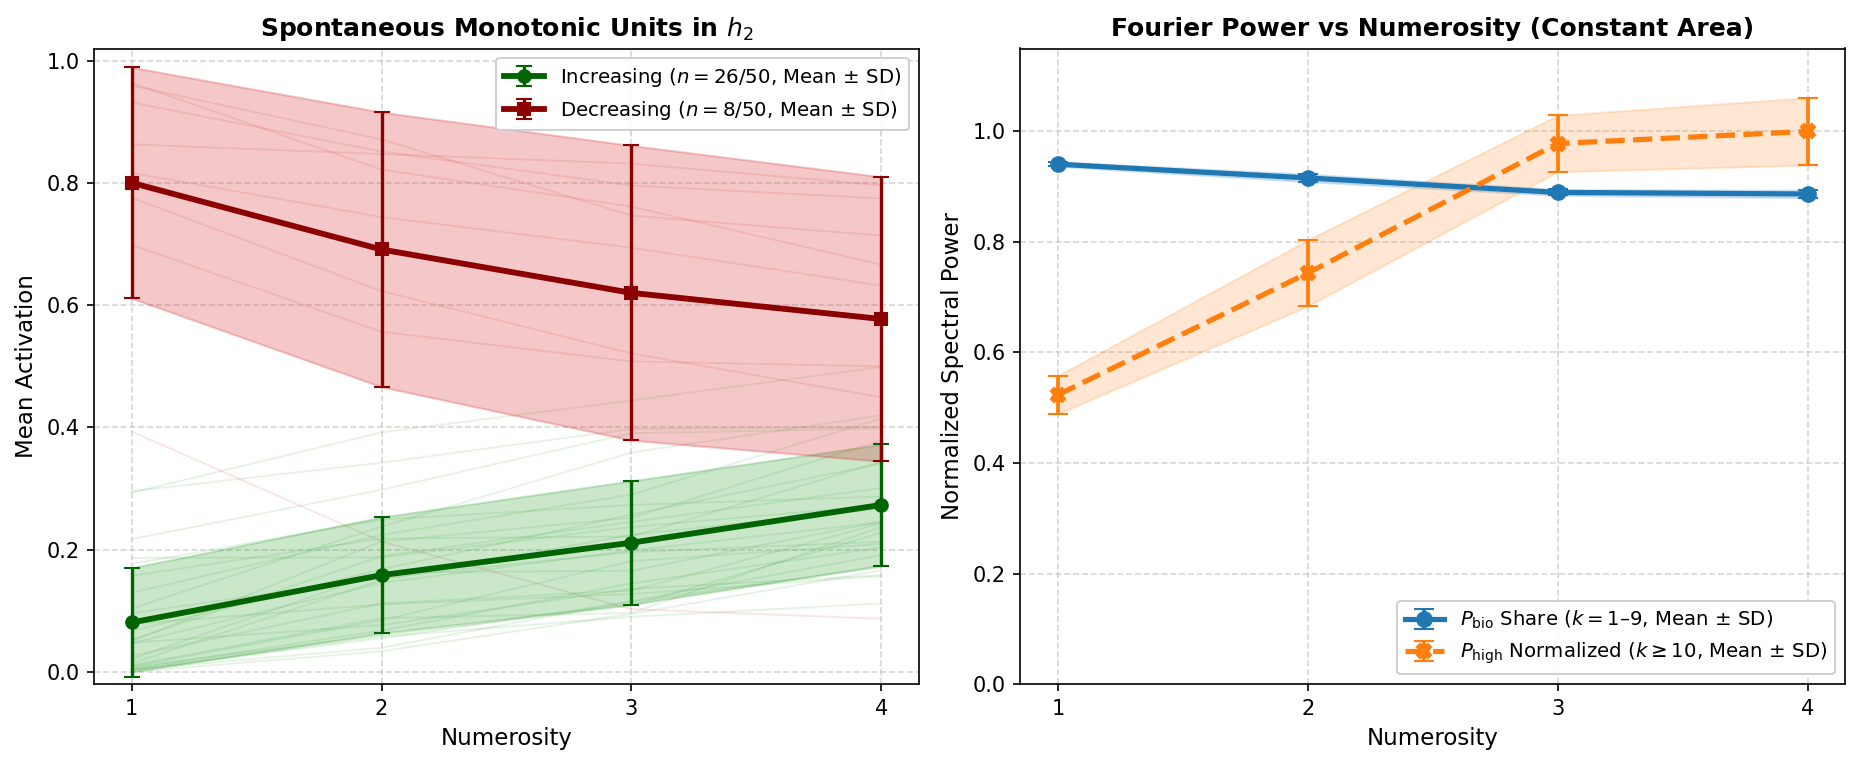

In [36]:
# =============================================================================
# SECTION 3.1 & 3.2: MONOTONIC UNITS AND FOURIER POWER ANALYSIS (FIGURE 3.1)
# =============================================================================
labels_np = labels_tensor.cpu().numpy()
pb_np = np.array(pb_list)
ph_np = np.array(ph_list)
train_num_range = np.array([1, 2, 3, 4])

# 1. Compute h2 activation profiles across all 10 trained iDBN networks
all_nets_inc_counts = []
all_nets_dec_counts = []
all_nets_mean_h2 = []

for net in trained_networks:
    _, ph2_all = net['idbn'].forward_features(dataset_v)
    h2_np = ph2_all.cpu().numpy()

    net_means = np.zeros((len(train_num_range), h2_np.shape[1]))
    for i, n in enumerate(train_num_range):
        mask = (labels_np == n)
        net_means[i, :] = h2_np[mask].mean(axis=0)

    diffs = np.diff(net_means, axis=0)
    inc_idx = np.where(np.all(diffs > 0, axis=0))[0]
    dec_idx = np.where(np.all(diffs < 0, axis=0))[0]

    all_nets_inc_counts.append(len(inc_idx))
    all_nets_dec_counts.append(len(dec_idx))
    all_nets_mean_h2.append(net_means)

print(f"Across n=10 networks -> Increasing h2 units: {np.mean(all_nets_inc_counts):.1f} ± {np.std(all_nets_inc_counts, ddof=1):.1f} / 50")
print(f"Across n=10 networks -> Decreasing h2 units: {np.mean(all_nets_dec_counts):.1f} ± {np.std(all_nets_dec_counts, ddof=1):.1f} / 50")

# Representative network (Network 0)
rep_means = all_nets_mean_h2[0]
rep_diffs = np.diff(rep_means, axis=0)
increasing_units = np.where(np.all(rep_diffs > 0, axis=0))[0]
decreasing_units = np.where(np.all(rep_diffs < 0, axis=0))[0]

# 2. Compute per-stimulus Fourier Power (P_bio share vs normalized P_high) on Constant-Area stimuli
pb_share_mean, pb_share_sd = [], []
ph_norm_mean, ph_norm_sd = [], []

max_ph_mean = max(ph_np[(labels_np == n) & const_area_mask].mean() for n in train_num_range)

for n in train_num_range:
    mask_const = (labels_np == n) & (const_area_mask == True)
    pb_vals = pb_np[mask_const]
    ph_vals = ph_np[mask_const]

    shares = pb_vals / (pb_vals + ph_vals)
    ph_scaled = ph_vals / max_ph_mean

    pb_share_mean.append(shares.mean())
    pb_share_sd.append(shares.std(ddof=1))
    ph_norm_mean.append(ph_scaled.mean())
    ph_norm_sd.append(ph_scaled.std(ddof=1))

pb_share_mean, pb_share_sd = np.array(pb_share_mean), np.array(pb_share_sd)
ph_norm_mean, ph_norm_sd = np.array(ph_norm_mean), np.array(ph_norm_sd)

print("\nFourier Power Diagnostics (Constant-Area Stimuli, Mean ± SD):")
for i, n in enumerate(train_num_range):
    print(f"  N={n} | P_bio share: {pb_share_mean[i]:.3f} ± {pb_share_sd[i]:.3f} | P_high norm: {ph_norm_mean[i]:.3f} ± {ph_norm_sd[i]:.3f}")

# 3. Plot Figure 3.1 with Mean ± 1 SD shaded bands and error bars
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), dpi=150)

# --- Panel A: Spontaneous Monotonic Units in h2 (Representative Network 0) ---
if len(increasing_units) > 0:
    inc_mean = rep_means[:, increasing_units].mean(axis=1)
    inc_sd = rep_means[:, increasing_units].std(axis=1, ddof=1 if len(increasing_units) > 1 else 0)
    axes[0].plot(train_num_range, rep_means[:, increasing_units],
                 color='#2ca02c', alpha=0.12, linewidth=0.9, zorder=1)
    axes[0].fill_between(train_num_range,
                         np.clip(inc_mean - inc_sd, 0.0, 1.0),
                         np.clip(inc_mean + inc_sd, 0.0, 1.0),
                         color='#2ca02c', alpha=0.25, zorder=2)
    axes[0].errorbar(train_num_range, inc_mean, yerr=inc_sd,
                     color='darkgreen', marker='o', markersize=6,
                     linewidth=2.8, capsize=4, elinewidth=1.6, zorder=4,
                     label=rf'Increasing ($n={len(increasing_units)}/50$, Mean $\pm$ SD)')

if len(decreasing_units) > 0:
    dec_mean = rep_means[:, decreasing_units].mean(axis=1)
    dec_sd = rep_means[:, decreasing_units].std(axis=1, ddof=1 if len(decreasing_units) > 1 else 0)
    axes[0].plot(train_num_range, rep_means[:, decreasing_units],
                 color='#d62728', alpha=0.12, linewidth=0.9, zorder=1)
    axes[0].fill_between(train_num_range,
                         np.clip(dec_mean - dec_sd, 0.0, 1.0),
                         np.clip(dec_mean + dec_sd, 0.0, 1.0),
                         color='#d62728', alpha=0.25, zorder=2)
    axes[0].errorbar(train_num_range, dec_mean, yerr=dec_sd,
                     color='darkred', marker='s', markersize=6,
                     linewidth=2.8, capsize=4, elinewidth=1.6, zorder=4,
                     label=rf'Decreasing ($n={len(decreasing_units)}/50$, Mean $\pm$ SD)')

axes[0].set_title(r"Spontaneous Monotonic Units in $h_2$", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Numerosity", fontsize=11)
axes[0].set_ylabel("Mean Activation", fontsize=11)
axes[0].set_xticks(train_num_range)
axes[0].set_ylim(-0.02, 1.02)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', fontsize=9.5, framealpha=0.9)

# --- Panel B: Fourier Power vs Numerosity (Constant Area, Mean ± 1 SD) ---
axes[1].fill_between(train_num_range,
                     pb_share_mean - pb_share_sd,
                     pb_share_mean + pb_share_sd,
                     color='#1f77b4', alpha=0.18, zorder=2)
axes[1].errorbar(train_num_range, pb_share_mean, yerr=pb_share_sd,
                 marker='o', markersize=7, color='#1f77b4', linestyle='-',
                 linewidth=2.5, capsize=5, elinewidth=1.8, zorder=4,
                 label=r'$P_{\mathrm{bio}}$ Share ($k=1$–$9$, Mean $\pm$ SD)')

axes[1].fill_between(train_num_range,
                     ph_norm_mean - ph_norm_sd,
                     ph_norm_mean + ph_norm_sd,
                     color='#ff7f0e', alpha=0.18, zorder=2)
axes[1].errorbar(train_num_range, ph_norm_mean, yerr=ph_norm_sd,
                 marker='X', markersize=7, color='#ff7f0e', linestyle='--',
                 linewidth=2.5, capsize=5, elinewidth=1.8, zorder=4,
                 label=r'$P_{\mathrm{high}}$ Normalized ($k \geq 10$, Mean $\pm$ SD)')

axes[1].set_title("Fourier Power vs Numerosity (Constant Area)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Numerosity", fontsize=11)
axes[1].set_ylabel("Normalized Spectral Power", fontsize=11)
axes[1].set_xticks(train_num_range)
axes[1].set_ylim(0.0, max(1.15, (ph_norm_mean + ph_norm_sd).max() + 0.08))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='lower right', fontsize=9.5, framealpha=0.9)

plt.tight_layout()
plt.savefig("monotonic_and_fourier.png", dpi=300, bbox_inches='tight')
plt.show()

Cell 6: The Empty Set and Distance Effect (Refers to Section 3.3)
This block generates completely novel test sets containing 0 to 6 items. It feeds them through the trained model to see if the "More-than" / "Less-than" delta-rule readout naturally prefers 0 when asked for the "lowest" value, replicating Howard et al. (2018).

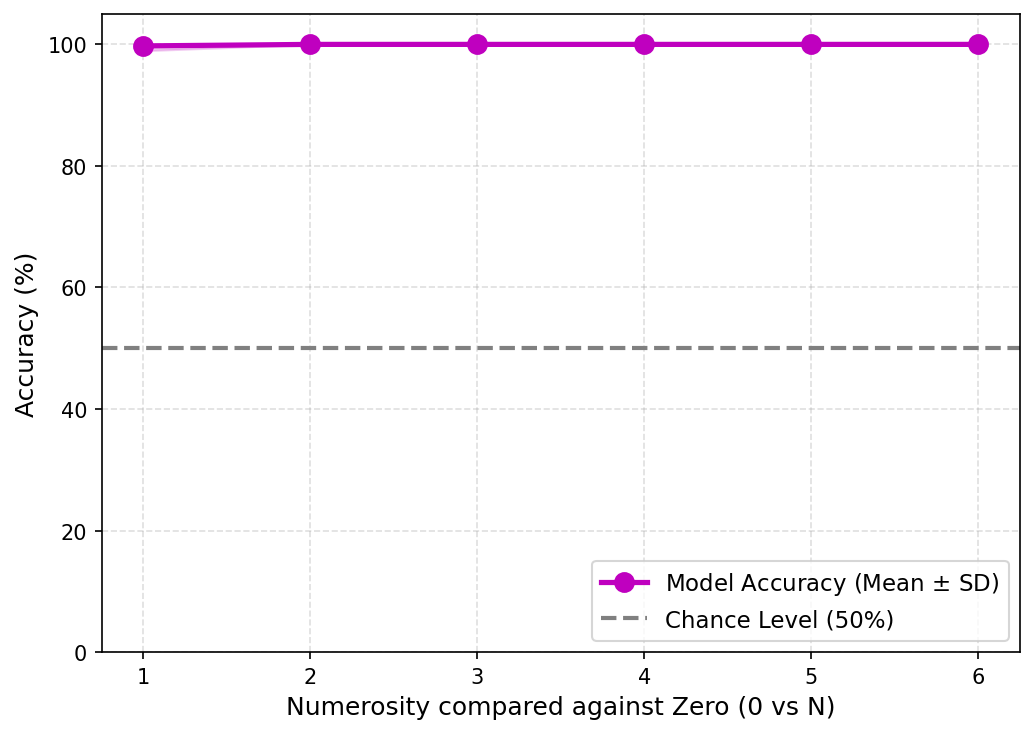

Learning Transfer Test (N in 1..4): 89.6% ± 1.4%
Rule Extrapolation Test (N=5):      88.3% ± 2.0%

Zero-Set Distance Effect Accuracies (Mean ± SD across n=10 networks):
  0 vs 1: 99.8% ± 0.8%
  0 vs 2: 100.0% ± 0.0%
  0 vs 3: 100.0% ± 0.0%
  0 vs 4: 100.0% ± 0.0%
  0 vs 5: 100.0% ± 0.0%
  0 vs 6: 100.0% ± 0.0%


In [37]:
# =============================================================================
# SECTION 3.3: TRANSFER, EXTRAPOLATION (N=5), AND THE ZERO-SET (FIGURE 3.5)
# =============================================================================
set_seed(1000)

test_v = []
test_labels = []
n_test_per_num = 40

for n in range(7):
    for _ in range(n_test_per_num):
        # Mix shapes and constant area on probe trials as in Howard et al. (2018)
        img = generate_stimulus(n, constant_area=True)
        omm_view, _, _ = apply_bee_optics(img)
        test_v.append(omm_view.flatten())
        test_labels.append(n)

test_v_tensor = torch.tensor(np.array(test_v), dtype=torch.float32).to(device)
test_labels_np = np.array(test_labels)
n_range = [1, 2, 3, 4, 5, 6]

all_zero_acc_less = []      # "Less-than" cohort choosing 0 over N
all_zero_acc_greater = []   # "Greater-than" cohort choosing N over 0
all_learning_acc = []       # Novel probe pairs within trained range {1..4} (both cohorts)
all_extrap5_acc = []        # Extrapolation pairs contrasting N=5 vs {1..4} (both cohorts)

for net in trained_networks:
    _, ph2_test = net['idbn'].forward_features(test_v_tensor)
    W_greater = net['W_out_greater']
    W_less = net['W_out_less']

    zero_acts = ph2_test[test_labels_np == 0]
    net_zero_less = []
    net_zero_greater = []

    # 1. Empty-Set (0 vs N) Distance Effect across N = 1..6
    for n in n_range:
        n_acts = ph2_test[test_labels_np == n]

        # Vectorized pairwise differences between all N=0 and N=n probe stimuli
        # delta_0_n = h2(0) - h2(n) for "Less-Than" rule (is 0 < n?)
        delta_0_n = zero_acts.unsqueeze(1) - n_acts.unsqueeze(0)  # (40, 40, 50)
        flat_delta_0_n = delta_0_n.reshape(-1, 50)

        y_less = torch.sigmoid(torch.mm(flat_delta_0_n, W_less))
        acc_less = (y_less > 0.5).float().mean().item() * 100.0
        net_zero_less.append(acc_less)

        # For "Greater-Than" rule: -delta_0_n = h2(n) - h2(0) (is n > 0?)
        y_greater = torch.sigmoid(torch.mm(-flat_delta_0_n, W_greater))
        acc_greater = (y_greater > 0.5).float().mean().item() * 100.0
        net_zero_greater.append(acc_greater)

    all_zero_acc_less.append(net_zero_less)
    all_zero_acc_greater.append(net_zero_greater)

    # 2. Novel Learning Test (All unequal pairs in {1, 2, 3, 4}, averaged across both cohorts)
    learn_correct, learn_total = 0.0, 0
    for n_high in [2, 3, 4]:
        for n_low in range(1, n_high):
            acts_h = ph2_test[test_labels_np == n_high]
            acts_l = ph2_test[test_labels_np == n_low]
            d_hl = (acts_h.unsqueeze(1) - acts_l.unsqueeze(0)).reshape(-1, 50)
            preds_g = (torch.sigmoid(torch.mm(d_hl, W_greater)) > 0.5).float()
            preds_l = (torch.sigmoid(torch.mm(-d_hl, W_less)) > 0.5).float()
            learn_correct += 0.5 * (preds_g.sum().item() + preds_l.sum().item())
            learn_total += preds_g.numel()
    all_learning_acc.append((learn_correct / learn_total) * 100.0)

    # 3. Extrapolation to N=5 (5 vs {1, 2, 3, 4}, averaged across both cohorts)
    ext_correct, ext_total = 0.0, 0
    acts_5 = ph2_test[test_labels_np == 5]
    for n_low in [1, 2, 3, 4]:
        acts_l = ph2_test[test_labels_np == n_low]
        d_5l = (acts_5.unsqueeze(1) - acts_l.unsqueeze(0)).reshape(-1, 50)
        preds_g = (torch.sigmoid(torch.mm(d_5l, W_greater)) > 0.5).float()
        preds_l = (torch.sigmoid(torch.mm(-d_5l, W_less)) > 0.5).float()
        ext_correct += 0.5 * (preds_g.sum().item() + preds_l.sum().item())
        ext_total += preds_g.numel()
    all_extrap5_acc.append((ext_correct / ext_total) * 100.0)

# Combine cohorts for the 0 vs N numerical distance curve (Figure 3.5)
zero_results_matrix = 0.5 * (np.array(all_zero_acc_less) + np.array(all_zero_acc_greater))
mean_vs_zero = np.mean(zero_results_matrix, axis=0)
std_vs_zero = np.std(zero_results_matrix, axis=0, ddof=1)

plt.figure(figsize=(7, 5), dpi=150)
plt.plot(n_range, mean_vs_zero, 'mo-', linewidth=2.5, markersize=9, label=r'Model Accuracy (Mean $\pm$ SD)')
plt.fill_between(n_range,
                 np.clip(mean_vs_zero - std_vs_zero, 0, 100),
                 np.clip(mean_vs_zero + std_vs_zero, 0, 100),
                 color='m', alpha=0.2)
plt.axhline(50, color='gray', linestyle='--', linewidth=2, label='Chance Level (50%)')
plt.xlabel("Numerosity compared against Zero (0 vs N)", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.ylim(0, 105)
plt.xticks(n_range)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.4, linestyle='--')
plt.tight_layout()
plt.savefig("zero_distance_effect.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Learning Transfer Test (N in 1..4): {np.mean(all_learning_acc):.1f}% ± {np.std(all_learning_acc, ddof=1):.1f}%")
print(f"Rule Extrapolation Test (N=5):      {np.mean(all_extrap5_acc):.1f}% ± {np.std(all_extrap5_acc, ddof=1):.1f}%")
print("\nZero-Set Distance Effect Accuracies (Mean ± SD across n=10 networks):")
for n, m_val, s_val in zip(n_range, mean_vs_zero, std_vs_zero):
    print(f"  0 vs {n}: {m_val:.1f}% ± {s_val:.1f}%")

Saves as architecture_diagram.png. You can reference this in Chapter 2 of your thesis.

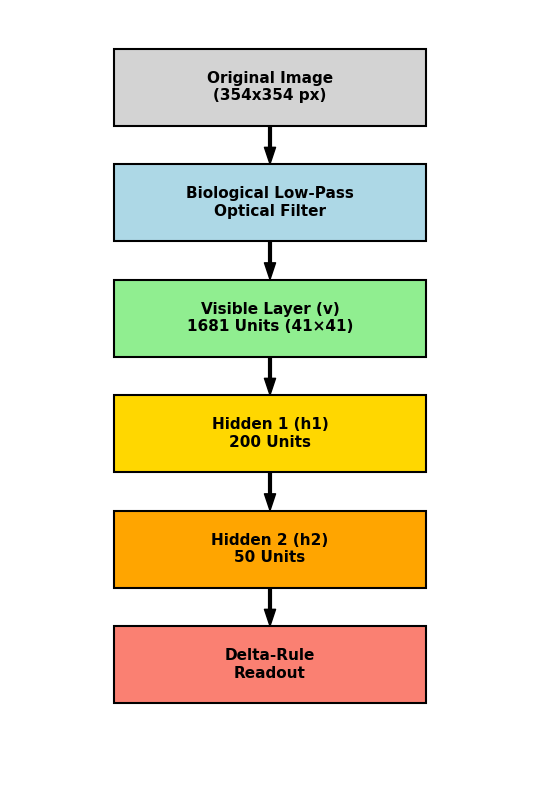

In [38]:
# ==============================================================================
# 1. Architecture Diagram (iDBN Topology) - Vertical Thesis Format
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Taller, narrower figure tailored for a portrait thesis page
fig, ax = plt.subplots(figsize=(5.5, 8))
ax.axis('off')

# Set explicit limits to maintain fixed internal proportions
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Vertical layout parameters
box_width = 0.6
box_height = 0.1
center_x = 0.5
left_x = center_x - (box_width / 2)
gap = 0.05
start_y = 0.95  # Starting near the top of the figure

# Define the layers and colors
layers = [
    {"label": "Original Image\n(354x354 px)", "color": "lightgray"},
    {"label": "Biological Low-Pass\nOptical Filter", "color": "lightblue"},
    {"label": "Visible Layer (v)\n1681 Units (41×41)", "color": "lightgreen"},
    {"label": "Hidden 1 (h1)\n200 Units", "color": "gold"},
    {"label": "Hidden 2 (h2)\n50 Units", "color": "orange"},
    {"label": "Delta-Rule\nReadout", "color": "salmon"}
]

boxes = []
current_y = start_y

# Generate coordinates and draw boxes top-to-bottom
for data in layers:
    box_bottom = current_y - box_height
    boxes.append({"top": current_y, "bottom": box_bottom})

    # Add Rectangle
    rect = patches.Rectangle((left_x, box_bottom), box_width, box_height,
                             linewidth=1.5, edgecolor='black', facecolor=data["color"], zorder=2)
    ax.add_patch(rect)

    # Add Text (Increased font size for print readability)
    ax.text(center_x, box_bottom + (box_height / 2), data["label"],
            ha='center', va='center', fontsize=11, fontweight='bold', zorder=3)

    # Move the Y-coordinate down for the next box
    current_y = box_bottom - gap

# Draw arrows pointing downwards between boxes
for i in range(len(boxes) - 1):
    current_box = boxes[i]
    next_box = boxes[i+1]

    start_arrow = (center_x, current_box["bottom"])
    end_arrow = (center_x, next_box["top"])

    ax.annotate('', xy=end_arrow, xytext=start_arrow,
                arrowprops=dict(facecolor='black', shrink=0, width=2, headwidth=8), zorder=1)

plt.tight_layout()
plt.savefig("architecture_diagram_vertical.png", dpi=300, bbox_inches='tight')
plt.show()

Saves as tsne_latent_space.png. Replace X_mock and y_labels with your actual ph2 output array and target labels.

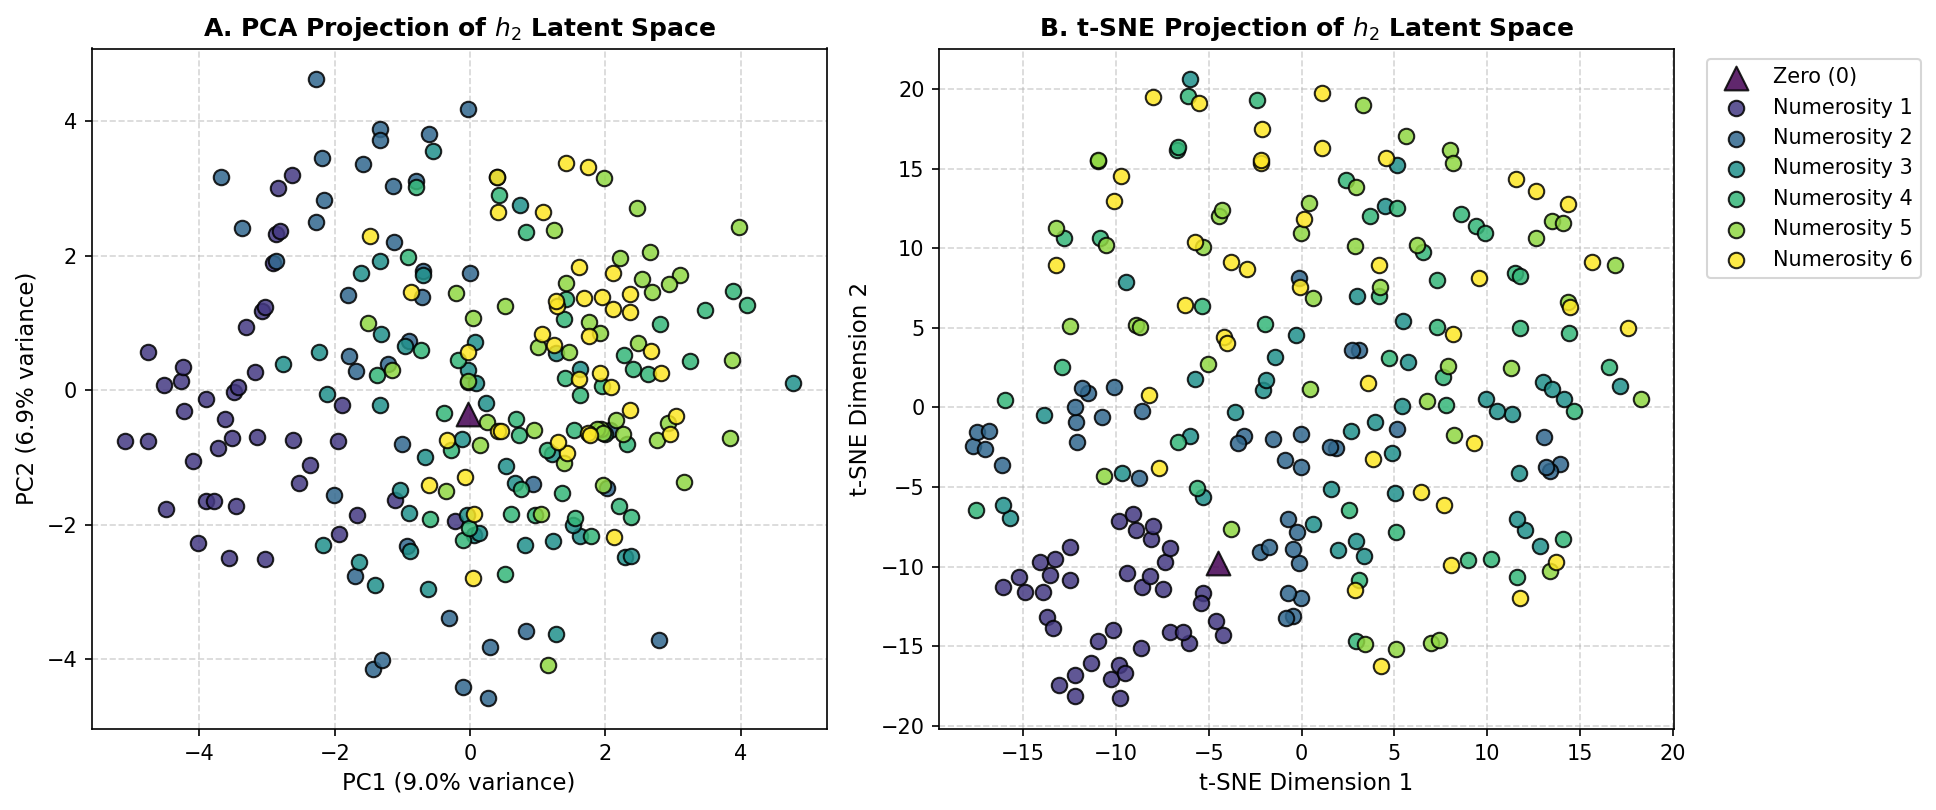

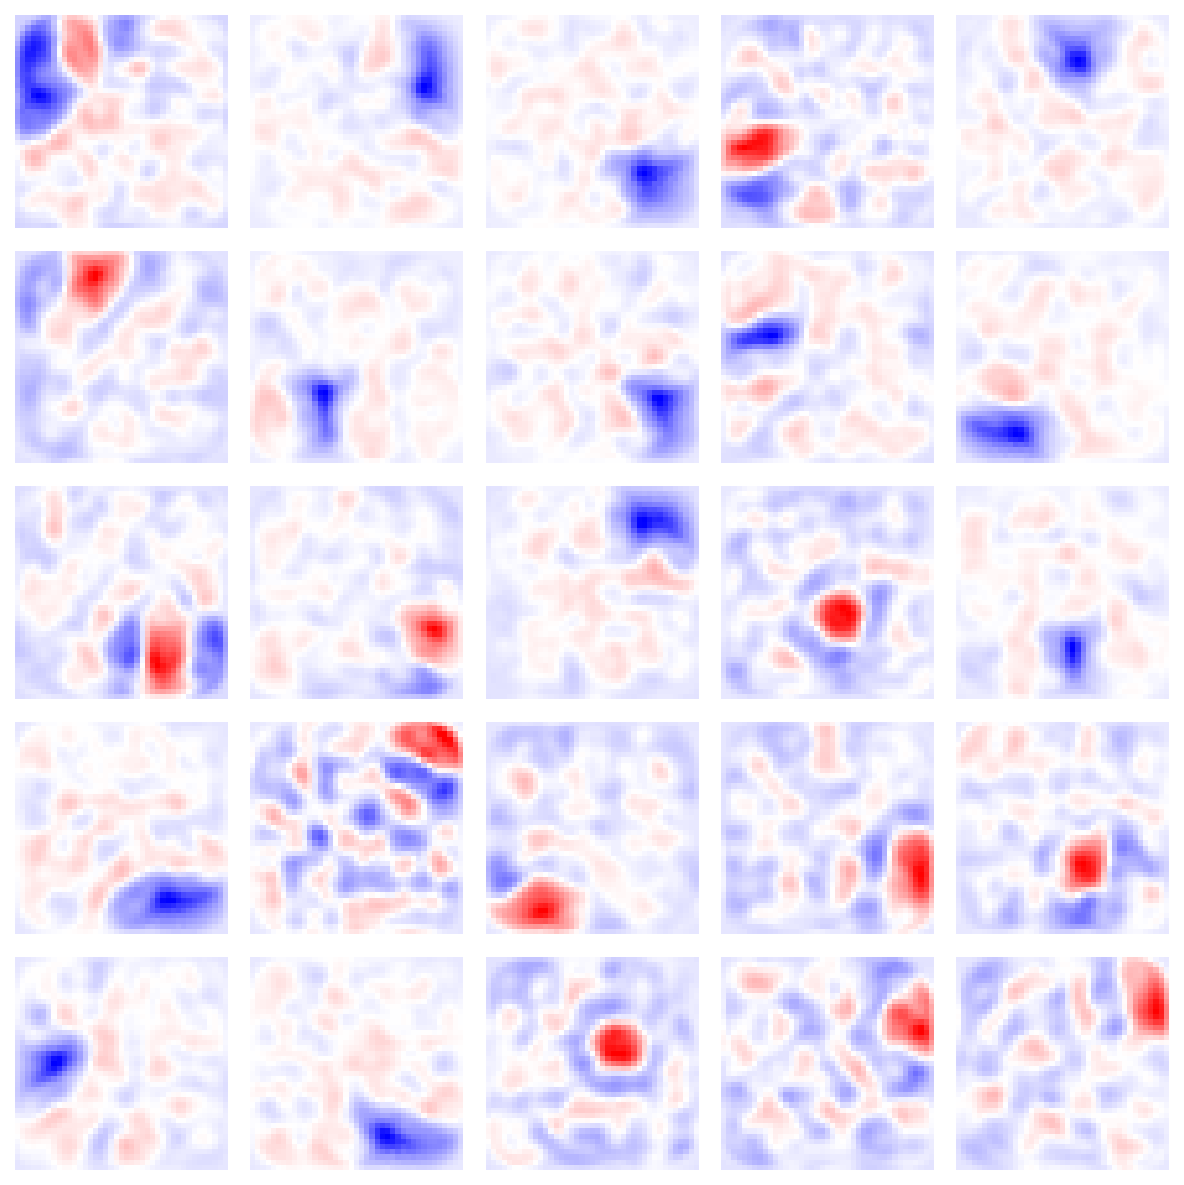

In [39]:
# =============================================================================
# SECTION 3.1: PCA & DEDUPLICATED t-SNE (FIG 3.2) AND TRAINED W1 WEIGHTS (FIG 3.3)
# =============================================================================
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.cm as cm

rep_idbn = trained_networks[0]['idbn']
_, ph2_tsne_tensor = rep_idbn.forward_features(test_v_tensor)
X_real_h2 = ph2_tsne_tensor.cpu().numpy()
y_real_labels = test_labels_np

# Deduplicate N=0 to a single point (all 40 empty-set vectors are mathematically identical)
keep_mask = (y_real_labels != 0)
zero_idx = np.where(y_real_labels == 0)[0][0]
keep_mask[zero_idx] = True

X_dedup = X_real_h2[keep_mask]
y_dedup = y_real_labels[keep_mask]
X_scaled = StandardScaler().fit_transform(X_dedup)

# --- 1. Figure 3.2: PCA + Deduplicated t-SNE ---
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
if np.corrcoef(X_pca[:, 0], y_dedup)[0, 1] < 0:
    X_pca[:, 0] *= -1
pca_var = pca.explained_variance_ratio_ * 100.0

tsne = TSNE(n_components=2, perplexity=25, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_scaled)
if np.corrcoef(X_tsne[:, 0], y_dedup)[0, 1] < 0:
    X_tsne[:, 0] *= -1

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
colors = cm.viridis(np.linspace(0, 1, 7))

for ax, emb, title, xl, yl in [
    (axes[0], X_pca, r"A. PCA Projection of $h_2$ Latent Space",
     f"PC1 ({pca_var[0]:.1f}% variance)",
     f"PC2 ({pca_var[1]:.1f}% variance)"),
    (axes[1], X_tsne, r"B. t-SNE Projection of $h_2$ Latent Space",
     "t-SNE Dimension 1", "t-SNE Dimension 2")
]:
    for i in range(7):
        idx = (y_dedup == i)
        label_name = "Zero (0)" if i == 0 else f"Numerosity {i}"
        marker = '^' if i == 0 else 'o'
        size = 130 if i == 0 else 55
        ax.scatter(emb[idx, 0], emb[idx, 1], color=colors[i], label=label_name,
                   alpha=0.85, edgecolors='k', marker=marker, s=size, zorder=5 if i == 0 else 2)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xl, fontsize=11)
    ax.set_ylabel(yl, fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[1].legend(bbox_to_anchor=(1.03, 1), loc='upper left')
plt.tight_layout()
plt.savefig("tsne_latent_space.png", dpi=300, bbox_inches='tight')
plt.show()

# --- 2. Figure 3.3: Real Trained W1 Receptive Fields (Network 0) ---
W1_real = rep_idbn.rbm1.W.detach().cpu().numpy()  # (n_hidden=200, n_visible=1681)

rng = np.random.default_rng(10)
selected_units = rng.choice(W1_real.shape[0], 25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(8, 8), dpi=150)
for i, ax in enumerate(axes.flat):
    rf = W1_real[selected_units[i], :].reshape(41, 41)
    vmax = np.max(np.abs(rf)) + 1e-8
    ax.imshow(rf, cmap='bwr', vmin=-vmax, vmax=vmax)
    ax.axis('off')

plt.tight_layout()
plt.savefig("receptive_fields.png", dpi=300, bbox_inches='tight')
plt.show()

Saves as incongruent_test_bar.png. Replace accuracies with the actual accuracy percentages calculated by your script.

Spectral Check -> Mean P_high (2 Edge-Disrupted Stars): 0.052248 > Mean P_high (3 Standard): 0.014190
Spectral Check -> Mean P_bio  (2 Edge-Disrupted Stars): 0.070680 vs Mean P_bio  (3 Standard): 0.109230


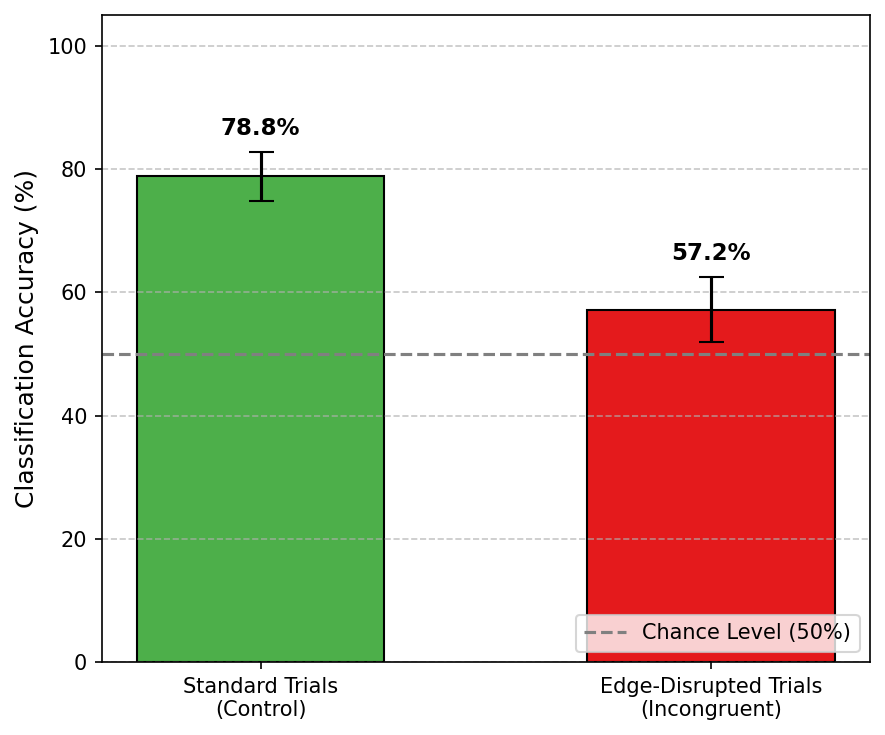

Standard Control Trials:        78.8% ± 4.0%
Edge-Disrupted Incongruent:     57.2% ± 5.2%
Equal (2-Star vs 2-Std) Choice: 67.4% ± 2.3% (Mean choice probability; 50% = unbiased)


In [40]:
# =============================================================================
# SECTION 3.2: PERFORMANCE ON EDGE-DISRUPTED INCONGRUENT TESTS (FIGURE 3.4)
# =============================================================================

def generate_edge_disrupted_stimulus(N_items, img_size=354, constant_area=True,
                                     n_points=10, modulation=0.65, max_restarts=200):
    """
    Generates an N-item stimulus using high-frequency multi-pointed star shapes
    whose total black surface area exactly matches generate_stimulus(), while
    artificially inflating boundary contour length and high spatial frequency (P_high),
    replicating MaBouDi et al. (2021).
    """
    if N_items <= 0:
        return np.ones((img_size, img_size), dtype=np.float32)

    area_jitter = np.random.uniform(0.97, 1.03)
    area_per_item = (CONST_TOTAL_AREA_PX * area_jitter) / N_items if constant_area else FIXED_ITEM_AREA_PX * area_jitter

    # Exact polar area of star r(phi) = R0 * (1 + alpha * cos(K * phi)) is pi * R0^2 * (1 + 0.5 * alpha^2)
    R0 = np.sqrt(area_per_item / (np.pi * (1.0 + 0.5 * (modulation**2))))
    max_r = int(np.ceil(R0 * (1.0 + modulation)))
    margin = max_r + 6

    y_grid, x_grid = np.meshgrid(np.arange(img_size), np.arange(img_size), indexing='ij')

    for _ in range(max_restarts):
        img = np.ones((img_size, img_size), dtype=np.float32)
        positions = []
        success = True

        for _ in range(N_items):
            placed = False
            for _ in range(400):
                cx = np.random.randint(margin, img_size - margin)
                cy = np.random.randint(margin, img_size - margin)

                if any(np.hypot(cx - px, cy - py) < (2 * max_r + 4) for (px, py) in positions):
                    continue

                dx = x_grid - cx
                dy = y_grid - cy
                r_dist = np.hypot(dx, dy)
                phi = np.arctan2(dy, dx)
                star_boundary = R0 * (1.0 + modulation * np.cos(n_points * phi))
                mask = (r_dist <= star_boundary)

                if not np.any(img[mask] == 0.0):
                    img[mask] = 0.0
                    positions.append((cx, cy))
                    placed = True
                    break

            if not placed:
                success = False
                break

        if success:
            return img

    raise RuntimeError(f"Failed to place {N_items} non-overlapping star shapes within {max_restarts} restarts.")


set_seed(2000)

n_control_trials = 100
standard_trials = []
incongruent_trials = []
equal_star_trials = []

ph_2star_list, ph_3std_list = [], []
pb_2star_list, pb_3std_list = [], []

for _ in range(n_control_trials):
    # 1. Standard Control Trial: 3 standard shapes vs 2 standard shapes
    img_3_std = generate_stimulus(3, constant_area=True)
    img_2_std = generate_stimulus(2, constant_area=True)
    v_3_std, pb_3, ph_3 = apply_bee_optics(img_3_std)
    v_2_std, _, _ = apply_bee_optics(img_2_std)
    standard_trials.append((v_3_std.flatten(), v_2_std.flatten()))

    # 2. Incongruent Trial (MaBouDi et al., 2021): 3 standard shapes vs 2 edge-disrupted stars
    img_2_star = generate_edge_disrupted_stimulus(2, constant_area=True)
    v_2_star, pb_2s, ph_2s = apply_bee_optics(img_2_star)
    incongruent_trials.append((v_3_std.flatten(), v_2_star.flatten()))

    # 3. Equal-Numerosity Trial: 2 edge-disrupted stars vs 2 standard shapes
    equal_star_trials.append((v_2_star.flatten(), v_2_std.flatten()))

    ph_2star_list.append(ph_2s)
    ph_3std_list.append(ph_3)
    pb_2star_list.append(pb_2s)
    pb_3std_list.append(pb_3)

print(f"Spectral Check -> Mean P_high (2 Edge-Disrupted Stars): {np.mean(ph_2star_list):.6f} > Mean P_high (3 Standard): {np.mean(ph_3std_list):.6f}")
print(f"Spectral Check -> Mean P_bio  (2 Edge-Disrupted Stars): {np.mean(pb_2star_list):.6f} vs Mean P_bio  (3 Standard): {np.mean(pb_3std_list):.6f}")

std_A = torch.tensor(np.array([t[0] for t in standard_trials]), dtype=torch.float32).to(device)
std_B = torch.tensor(np.array([t[1] for t in standard_trials]), dtype=torch.float32).to(device)

inc_A = torch.tensor(np.array([t[0] for t in incongruent_trials]), dtype=torch.float32).to(device)
inc_B = torch.tensor(np.array([t[1] for t in incongruent_trials]), dtype=torch.float32).to(device)

eq_A = torch.tensor(np.array([t[0] for t in equal_star_trials]), dtype=torch.float32).to(device)
eq_B = torch.tensor(np.array([t[1] for t in equal_star_trials]), dtype=torch.float32).to(device)

all_standard_acc = []
all_incongruent_acc = []
all_equal_star_pref = []

for net in trained_networks:
    idbn = net['idbn']
    W_greater = net['W_out_greater']
    W_less = net['W_out_less']

    # Standard 3 vs 2 accuracy (averaged across Greater-Than and Less-Than cohorts)
    _, h2_std_3 = idbn.forward_features(std_A)
    _, h2_std_2 = idbn.forward_features(std_B)
    d_std = h2_std_3 - h2_std_2
    acc_g_std = (torch.sigmoid(torch.mm(d_std, W_greater)) > 0.5).float().mean().item() * 100.0
    acc_l_std = (torch.sigmoid(torch.mm(-d_std, W_less)) > 0.5).float().mean().item() * 100.0
    all_standard_acc.append(0.5 * (acc_g_std + acc_l_std))

    # Incongruent 3-Standard vs 2-Star accuracy (True numerosity choice despite high P_high on 2-Star)
    _, h2_inc_3 = idbn.forward_features(inc_A)
    _, h2_inc_2star = idbn.forward_features(inc_B)
    d_inc = h2_inc_3 - h2_inc_2star
    acc_g_inc = (torch.sigmoid(torch.mm(d_inc, W_greater)) > 0.5).float().mean().item() * 100.0
    acc_l_inc = (torch.sigmoid(torch.mm(-d_inc, W_less)) > 0.5).float().mean().item() * 100.0
    all_incongruent_acc.append(0.5 * (acc_g_inc + acc_l_inc))

    # Equal 2-Star vs 2-Standard mean choice probability on "greater-than" readout (50% = unbiased)
    _, h2_eq_2star = idbn.forward_features(eq_A)
    _, h2_eq_2std = idbn.forward_features(eq_B)
    d_eq = h2_eq_2star - h2_eq_2std
    pref_star = torch.sigmoid(torch.mm(d_eq, W_greater)).mean().item() * 100.0
    all_equal_star_pref.append(pref_star)

mean_standard, std_standard = np.mean(all_standard_acc), np.std(all_standard_acc, ddof=1)
mean_incongruent, std_incongruent = np.mean(all_incongruent_acc), np.std(all_incongruent_acc, ddof=1)

# Plot Figure 3.4 with 10-network sample SD error bars
accuracies = [mean_standard, mean_incongruent]
std_devs = [std_standard, std_incongruent]
bar_labels = ['Standard Trials\n(Control)', 'Edge-Disrupted Trials\n(Incongruent)']

plt.figure(figsize=(6, 5), dpi=150)
bars = plt.bar(bar_labels, accuracies, yerr=std_devs, capsize=6,
               color=['#4daf4a', '#e41a1c'], edgecolor='black', width=0.55)

for bar, sd in zip(bars, std_devs):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + sd + 2.0,
             f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.ylim(0, 105)
plt.axhline(50, color='gray', linestyle='--', linewidth=1.5, label="Chance Level (50%)")
plt.ylabel('Classification Accuracy (%)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("incongruent_test_bar.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Standard Control Trials:        {mean_standard:.1f}% ± {std_standard:.1f}%")
print(f"Edge-Disrupted Incongruent:     {mean_incongruent:.1f}% ± {std_incongruent:.1f}%")
print(f"Equal (2-Star vs 2-Std) Choice: {np.mean(all_equal_star_pref):.1f}% ± {np.std(all_equal_star_pref, ddof=1):.1f}% (Mean choice probability; 50% = unbiased)")

In [41]:
# =============================================================================
# CELL 10: COMPLETE STATISTICAL ANALYSIS & LATEX-READY OUTPUT (n=10 NETWORKS)
# =============================================================================
from scipy import stats

def format_p(p_val):
    return "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

def format_ttest(scores, chance=50.0):
    scores = np.asarray(scores, dtype=float)
    mean_v = np.mean(scores)
    std_v = np.std(scores, ddof=1)
    df = len(scores) - 1
    if np.isclose(std_v, 0.0):
        return f"{mean_v:.1f} \\pm 0.0\\% (ceiling: all {len(scores)}/{len(scores)} networks = {mean_v:.1f}\\%)"
    t_stat, p_val = stats.ttest_1samp(scores, chance)
    return f"{mean_v:.1f} \\pm {std_v:.1f}\\% (t({df}) = {t_stat:.2f}, {format_p(p_val)})"

print("=== 0. SECTION 3.1: MONOTONIC UNITS & PCA VARIANCE ===")
print(f"Increasing h2 units (n=10 nets): {np.mean(all_nets_inc_counts):.1f} \\pm {np.std(all_nets_inc_counts, ddof=1):.1f} / 50")
print(f"Decreasing h2 units (n=10 nets): {np.mean(all_nets_dec_counts):.1f} \\pm {np.std(all_nets_dec_counts, ddof=1):.1f} / 50")
print(f"Representative Network 0:        n={len(increasing_units)} increasing, n={len(decreasing_units)} decreasing")
print(f"PCA Explained Variance:          PC1 = {pca_var[0]:.1f}%, PC2 = {pca_var[1]:.1f}% (Total = {pca_var.sum():.1f}%)")

print("\n=== 1. SECTION 3.2: SPECTRAL CHECK & EDGE-DISRUPTED TESTS (FIG 3.4) ===")
print(f"P_bio share (N=1..4):            {pb_share_mean[0]:.3f} -> {pb_share_mean[-1]:.3f}")
print(f"P_high norm (N=1..4):            {ph_norm_mean[0]:.3f} -> {ph_norm_mean[-1]:.3f}")
print(f"Mean P_high (2-Star vs 3-Std):   {np.mean(ph_2star_list):.4f} vs {np.mean(ph_3std_list):.4f}")
print(f"Mean P_bio  (2-Star vs 3-Std):   {np.mean(pb_2star_list):.4f} vs {np.mean(pb_3std_list):.4f}")
print(f"Standard Control (3 vs 2):       {format_ttest(all_standard_acc)}")
print(f"Edge-Disrupted (3 Std vs 2 Star):{format_ttest(all_incongruent_acc)}")
print(f"Equal Control (2 Star vs 2 Std): {format_ttest(all_equal_star_pref)} [Mean choice probability]")

t_paired, p_paired = stats.ttest_rel(all_standard_acc, all_incongruent_acc)
print(f"Paired t-test (Std vs Incong.):  t(9) = {t_paired:.2f}, {format_p(p_paired)}")

print("\n=== 2. SECTION 3.3: LEARNING, EXTRAPOLATION & ZERO-SET (FIG 3.5) ===")
print(f"Learning Transfer (N in 1..4):   {format_ttest(all_learning_acc)}")
print(f"Extrapolation to N=5:            {format_ttest(all_extrap5_acc)}")
for idx, n in enumerate(n_range):
    accs = zero_results_matrix[:, idx]
    print(f"0 vs {n}:                          {format_ttest(accs)}")

slopes = [stats.linregress(n_range, zero_results_matrix[i, :]).slope for i in range(len(trained_networks))]
t_slope, p_slope = stats.ttest_1samp(slopes, 0.0)
print(f"Distance Effect Linear Slope:    {np.mean(slopes):+.2f} \\pm {np.std(slopes, ddof=1):.2f}%/unit (t(9) = {t_slope:.2f}, {format_p(p_slope)})")

=== 0. SECTION 3.1: MONOTONIC UNITS & PCA VARIANCE ===
Increasing h2 units (n=10 nets): 26.2 \pm 2.3 / 50
Decreasing h2 units (n=10 nets): 6.9 \pm 1.7 / 50
Representative Network 0:        n=26 increasing, n=8 decreasing
PCA Explained Variance:          PC1 = 9.0%, PC2 = 6.9% (Total = 15.9%)

=== 1. SECTION 3.2: SPECTRAL CHECK & EDGE-DISRUPTED TESTS (FIG 3.4) ===
P_bio share (N=1..4):            0.941 -> 0.887
P_high norm (N=1..4):            0.523 -> 1.000
Mean P_high (2-Star vs 3-Std):   0.0522 vs 0.0142
Mean P_bio  (2-Star vs 3-Std):   0.0707 vs 0.1092
Standard Control (3 vs 2):       78.8 \pm 4.0\% (t(9) = 22.96, p < 0.001)
Edge-Disrupted (3 Std vs 2 Star):57.2 \pm 5.2\% (t(9) = 4.36, p = 0.002)
Equal Control (2 Star vs 2 Std): 67.4 \pm 2.3\% (t(9) = 23.77, p < 0.001) [Mean choice probability]
Paired t-test (Std vs Incong.):  t(9) = 18.68, p < 0.001

=== 2. SECTION 3.3: LEARNING, EXTRAPOLATION & ZERO-SET (FIG 3.5) ===
Learning Transfer (N in 1..4):   89.6 \pm 1.4\% (t(9) = 88.92, p

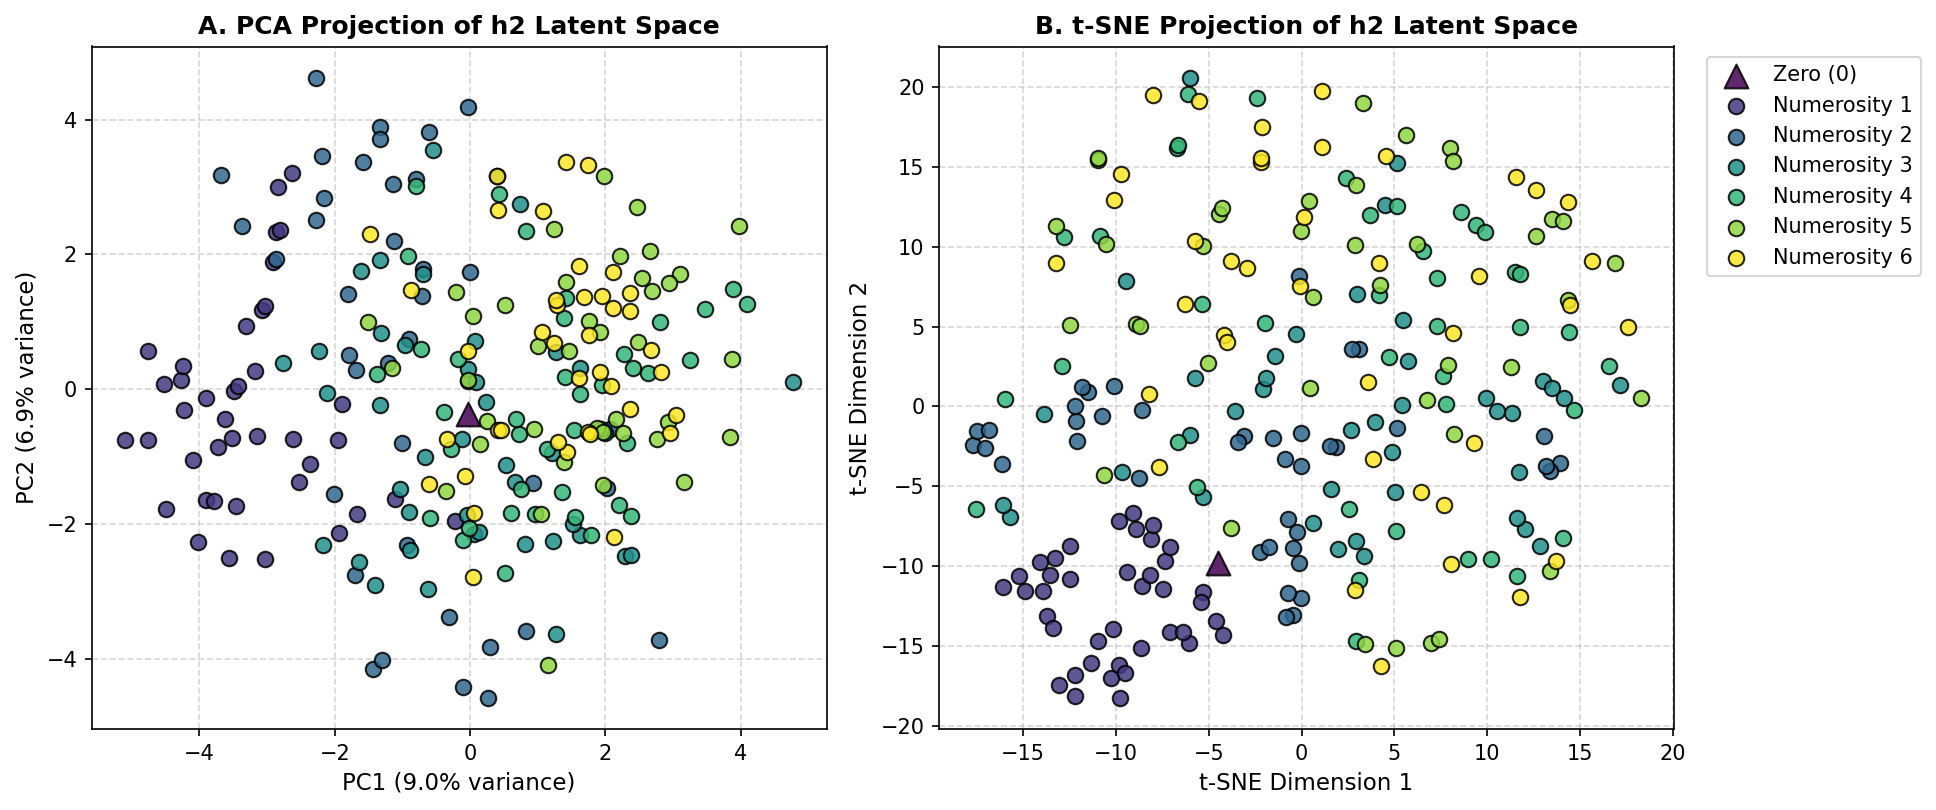

In [42]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.cm as cm

rep_idbn = trained_networks[0]['idbn']
_, ph2_tsne_tensor = rep_idbn.forward_features(test_v_tensor)
X_real_h2 = ph2_tsne_tensor.cpu().numpy()
y_real_labels = test_labels_np

# Deduplicate N=0 to a single point (all 40 empty-set vectors are mathematically identical)
keep_mask = (y_real_labels != 0)
zero_idx = np.where(y_real_labels == 0)[0][0]
keep_mask[zero_idx] = True

X_dedup = X_real_h2[keep_mask]
y_dedup = y_real_labels[keep_mask]
X_scaled = StandardScaler().fit_transform(X_dedup)

# Panel A: PCA (preserves true global linear geometry + variance explained)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
if np.corrcoef(X_pca[:, 0], y_dedup)[0, 1] < 0:
    X_pca[:, 0] *= -1

# Panel B: Deduplicated t-SNE (N=0 now retains its true affinity to N=1)
tsne = TSNE(n_components=2, perplexity=25, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_scaled)
if np.corrcoef(X_tsne[:, 0], y_dedup)[0, 1] < 0:
    X_tsne[:, 0] *= -1

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
colors = cm.viridis(np.linspace(0, 1, 7))

for ax, emb, title, xl, yl in [
    (axes[0], X_pca, "A. PCA Projection of h2 Latent Space",
     f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)",
     f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"),
    (axes[1], X_tsne, "B. t-SNE Projection of h2 Latent Space",
     "t-SNE Dimension 1", "t-SNE Dimension 2")
]:
    for i in range(7):
        idx = (y_dedup == i)
        label_name = "Zero (0)" if i == 0 else f"Numerosity {i}"
        marker = '^' if i == 0 else 'o'
        size = 130 if i == 0 else 55
        ax.scatter(emb[idx, 0], emb[idx, 1], color=colors[i], label=label_name,
                   alpha=0.85, edgecolors='k', marker=marker, s=size, zorder=5 if i == 0 else 2)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xl, fontsize=11)
    ax.set_ylabel(yl, fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[1].legend(bbox_to_anchor=(1.03, 1), loc='upper left')
plt.tight_layout()
plt.savefig("tsne_latent_space.png", dpi=300, bbox_inches='tight')
plt.show()